# Mixed Protocol Networks

## Introduction

**openfe** provides a number of protocols to estimate free energy differences, each with their own areas of applicability and limitations, suited to answering different types of scientific questions. While traditionally these protocols have been used in isolation, it is possible, thanks to the interchangeable nature of **openfe**, to combine them into a single network of transformations to leverage the strengths of each protocol.

This notebook demonstrates one way to create a mixed protocol network, combining two relative binding free energy approaches: the [Relative Hybrid Topology Protocol](https://docs.openfree.energy/en/latest/guide/protocols/relativehybridtopology.html#userguide-relative-hybrid-topology-protocol) and the [Separated Topologies Protocol](https://docs.openfree.energy/en/latest/guide/protocols/septop.html) to compute absolute binding affinities of a set of small molecules. A complete list of the available protocols along with their strengths and limitations can be found in the [protocol overview](https://docs.openfree.energy/en/latest/guide/protocols/index.html).

## Overview

In this tutorial, we will demonstrate how to create a mixed protocol network to estimate absolute binding free energies for `three` distinct ligand scaffold series bound to $\beta$-secretase 1 (BACE1) taken from [Baumann et al.](https://doi.org/10.1021/acs.jctc.3c00282). The dataset contains a total of 18 ligands with 6 ligands in each of the three unique scaffold series grouped as `biaryl`, `spirocyclic` and `amide`, examples of each are shown below:

<img src="assets/series.png" width="300">

While each subset of ligands forms a congeneric series suitable for the hybrid topology approach, connections between the series are more challenging due to the large structural differences between the scaffolds. To overcome this, we will use the separated topologies approach to connect the three series together. Here we present one possible way to construct a mixed protocol with minimal manual intervention which can be broken down into the following steps:

- Plan a single LOMAP-style hybrid topology binding free energy network with the Kartograf atom mapper and default LOMAP scorer
- Identify edges within this network between the three distinct series that are not suitable for the hybrid topology approach
- Build the transformations for the network, assigning the appropriate protocol to each transformation
- Analyze the results to estimate the absolute binding free energies for each ligand

# Load and classify the ligands

First, load the ligands from the provided SDF file and map each ligand name to its series. Convert the ligands to `SmallMoleculeComponents` for use with **openfe**.

<div alert class="alert alert-info"><b>Note:</b> Ligands should have partial charges assigned before planning the network. Here, we use pre-charged ligands, but charges can also be generated via the CLI or API.</div>
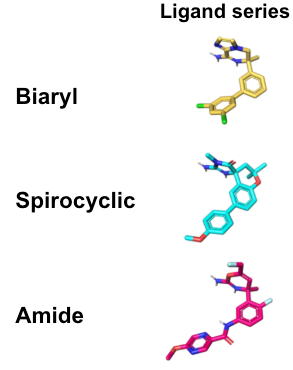

In [1]:
from rdkit import Chem
from gufe import SmallMoleculeComponent

ligands_file = "inputs/ligands.sdf"

supplier = Chem.SDMolSupplier(ligands_file, removeHs=False)
ligands = [SmallMoleculeComponent.from_rdkit(mol) for mol in supplier if mol is not None]

# Define a mapping between the ligand names and their respective series
ligand_series_mapping = {
    "lig_02": "biaryl",
    "lig_03": "biaryl",
    "lig_04": "biaryl",
    "lig_05": "biaryl",
    "lig_06": "biaryl",
    "lig_07": "biaryl",
    "lig_11": "spirocyclic",
    "lig_13": "spirocyclic",
    "lig_16": "spirocyclic",
    "lig_1a": "spirocyclic",
    "lig_32": "spirocyclic",
    "lig_36": "spirocyclic",
    "lig_41": "amide",
    "lig_45": "amide",
    "lig_67": "amide",
    "lig_69": "amide",
    "lig_74": "amide",
    "lig_81": "amide",
}

# Creating the `LigandNetwork`

Next we will create a single `LigandNetwork` containing all 18 ligands. This network will be used to identify edges between the three series that are not suitable for the hybrid topology approach, and will be assigned the separated topologies protocol later. In order to create a `LigandNetwork`, we need to define three components:

* **Atom Mapper**: Proposes potential atom mappings (descriptions of the alchemical change) for pairs of ligands. We will use the `KartografAtomMapper`.
* **Scorer**: Given an atom mapping, provides an estimate of the quality of that mapping (higher scores are better). We will use `default_lomap_scorer`.
* **Network Planner**: Creates the actual `LigandNetwork`; different network planners provide different strategies. We will create a `LOMAP` redundant network with the `generate_lomap_network` method.


In [2]:
import openfe

# Build the mapper using the default settings
mapper = openfe.KartografAtomMapper()
# Use the default LOMAP scorer to score the proposed atom mappings
scorer = openfe.lomap_scorers.default_lomap_score
# Use the LOMAP network planner to generate a redundant network
network_planner = openfe.ligand_network_planning.generate_lomap_network

# Build the network using the configured mapper, scorer, and network planner
network = network_planner(
    ligands=ligands,
    mappers=[mapper],
    scorer=scorer
)

INFO:root:Trying to remove edge 10-11 with similarity 0.670320
INFO:root:Checking edge deletion on distance-to-actives 0 vs 0
INFO:root:Removed edge 10-11
INFO:root:Trying to remove edge 7-8 with similarity 0.670320
INFO:root:Checking edge deletion on distance-to-actives 0 vs 0
INFO:root:Removed edge 7-8
INFO:root:Trying to remove edge 6-11 with similarity 0.704688
INFO:root:Rejecting edge deletion on cycle covering
INFO:root:Trying to remove edge 7-10 with similarity 0.778801
INFO:root:Checking edge deletion on distance-to-actives 0 vs 0
INFO:root:Removed edge 7-10
INFO:root:Trying to remove edge 8-10 with similarity 0.778801
INFO:root:Rejecting edge deletion on cycle covering
INFO:root:Trying to remove edge 7-11 with similarity 0.818731
INFO:root:Rejecting edge deletion on cycle covering
INFO:root:Trying to remove edge 6-7 with similarity 0.818731
INFO:root:Rejecting edge deletion on cycle covering
INFO:root:Trying to remove edge 6-8 with similarity 0.818731
INFO:root:Rejecting edge 

## Visualize the `LigandNetwork`

Now we can visualize the `LigandNetwork` while highlighting the three distinct series using colours to match the examples shown above. The `biaryl` series is shown in yellow, the `spirocyclic` series in cyan, and the `amide` series in magenta. Edges between the series are shown in red while edges within the series are shown in black.

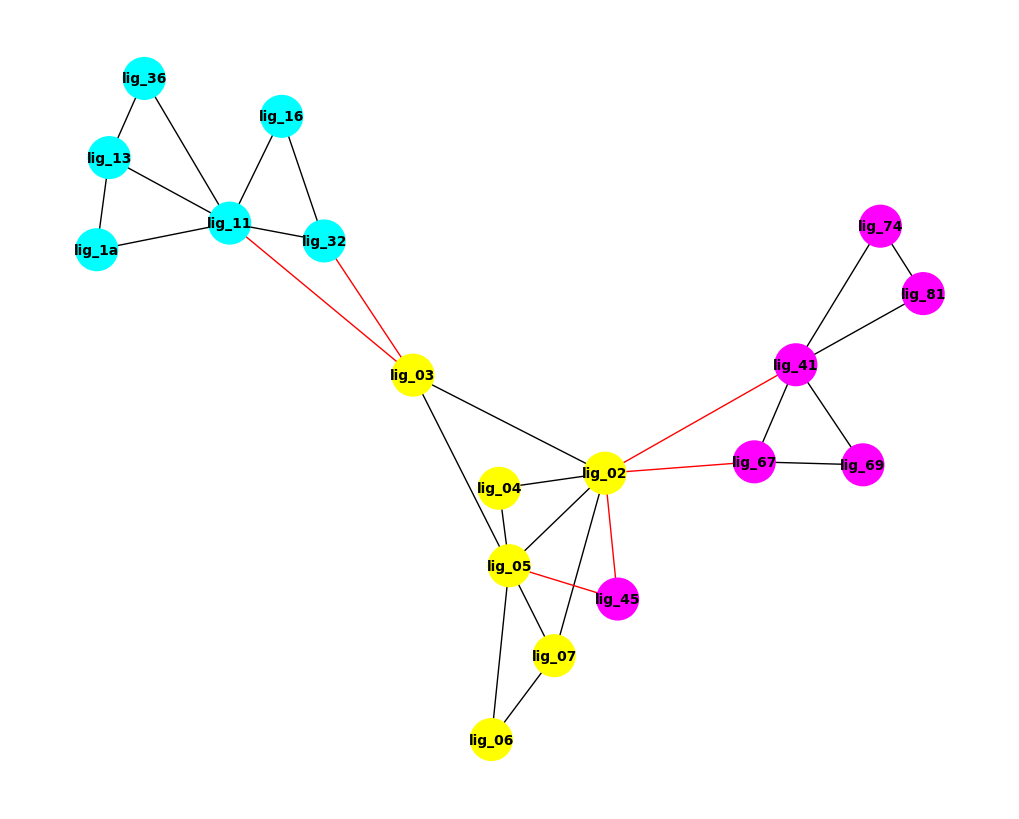

In [3]:
%matplotlib inline
import networkx as nx
import matplotlib.pyplot as plt

series_to_color = {
    "biaryl": "yellow",
    "spirocyclic": "cyan",
    "amide": "magenta"
}

network_graph = nx.Graph()
for edge in network.edges:
    network_graph.add_edge(edge.componentA.name, edge.componentB.name)
pos = nx.spring_layout(network_graph, seed=1)
node_colors = [series_to_color[ligand_series_mapping[node]] for node in network_graph.nodes()]
edge_colors = ["black" if ligand_series_mapping[edge[0]] == ligand_series_mapping[edge[1]] else "red" for edge in network_graph.edges()]
plt.figure(figsize=(10, 8))
nx.draw(network_graph, pos, with_labels=True, node_color=node_colors, edge_color=edge_colors, node_size=900, font_size=10, font_color='black', font_weight='bold')
plt.axis("off")
plt.show()

## Inspecting the atom mappings


Now we can compare atom mappings and scores for edges between and within the series. First, let's inspect an edge between the `biaryl` and `spirocyclic` series, connecting ligands `lig_03` and `lig_11`. The mapping and its score are shown below. The low score reflects the large number of alchemical atoms and suggests that calculations for this edge may be challenging to converge with the hybrid topology approach.

<div alert class="alert alert-info"><b>Reminder:</b> Shared core (mapped) atoms are shown in black, and atoms unique to each end state are shown in red. Mapped atoms whose elements change during the simulation are shown in blue.</div>

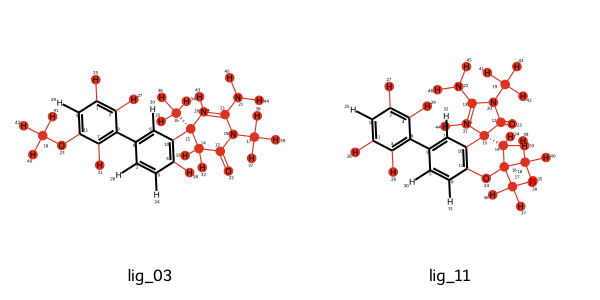

In [4]:
edge = [edge for edge in network.edges if {edge.componentA.name, edge.componentB.name} == {"lig_03", "lig_11"}][0]
edge

In [5]:
# Higher score is better
edge.annotations

{'score': 0.008208499862389881}

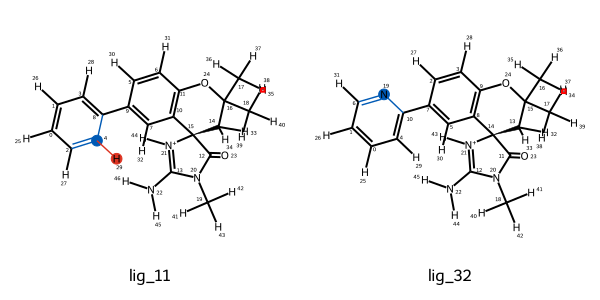

In [6]:
# Now find an edge within the spirocyclic series
edge = [edge for edge in network.edges if {edge.componentA.name, edge.componentB.name} == {"lig_11", "lig_32"}][0]
edge


In [7]:
# Higher score is better
edge.annotations

{'score': 0.951229424500714}

# Configure the `Protocols`

Before building the network transformations, configure the settings for both the hybrid topology and separated topologies protocols. By default, the protocols use the same small molecule force field, if you want to use a different force field this setting should be changed in both protocols as shown. We also use `_adaptive_settings` to adjust settings for each system. This is particularly useful for the hybrid topology protocol, which adjusts solvent padding based on whether a receptor is present.

In [8]:
from openfe.protocols.openmm_rfe import RelativeHybridTopologyProtocol
from openfe.protocols.openmm_septop import SepTopProtocol

# Configure the small molecule force field to be used by both protocols and the number of repeats per execution of the protocol
small_molecule_forcefield = "openff-2.3.0"
default_hybrid_settings = RelativeHybridTopologyProtocol.default_settings()
default_hybrid_settings.forcefield_settings.small_molecule_forcefield = small_molecule_forcefield
default_hybrid_settings.protocol_repeats = 1

default_septop_settings = SepTopProtocol.default_settings()
default_septop_settings.forcefield_settings.small_molecule_forcefield = small_molecule_forcefield
default_septop_settings.protocol_repeats = 1

/Users/joshua/mambaforge/envs/openfe_dev/lib/python3.12/site-packages/Bio/Application/__init__.py:39: BiopythonDeprecationWarning: The Bio.Application modules and modules relying on it have been deprecated.

Due to the on going maintenance burden of keeping command line application
wrappers up to date, we have decided to deprecate and eventually remove these
modules.

We instead now recommend building your command line and invoking it directly
with the subprocess module.
  warnings.warn(


# Building the `Transformation`

Now we can build the transformations for this network, assigning the appropriate protocol for each transformation. Here we will use the hybrid topology protocol for edges within each series and the separated topologies protocol for edges between the series.

Each protocol has different requirements for the `ChemicalSystem` compositions that represent the transformation's end states. The hybrid topology protocol requires you to construct the `complex` and `solvent` legs as separate `Transformation` objects, while the separated topologies protocol runs both legs within a single `Transformation`. The code below shows how to build transformations for both protocols with the appropriate `ChemicalSystem` objects. For more information about each protocol's requirements, see the [examples documentation](https://docs.openfree.energy/en/stable/guide/setup/chemical_systems_and_thermodynamic_cycles.html#system-composition-examples).

In [9]:
from openfe.protocols.openmm_rfe import RelativeHybridTopologyProtocolSettings
from openfe.protocols.openmm_septop import SepTopSettings

# load the receptor from the provided PDB file and create the solvent component
protein = openfe.ProteinComponent.from_pdb_file("inputs/protein.pdb")
solvent = openfe.SolventComponent()


# define helper functions to build the transformations for each protocol
def build_hybrid_topology_transformation(
    edge: openfe.LigandAtomMapping,
    default_settings: RelativeHybridTopologyProtocolSettings,
    protein_comp: openfe.ProteinComponent,
    solvent_comp: openfe.SolventComponent
) -> list[openfe.Transformation]:
    """Build the complex and solvent leg transformations for a given ligand atom mapping using the hybrid topology protocol."""
    transformations = []
    for leg in ["solvent", "complex"]:
        state_a_dict = {"ligand": edge.componentA, "solvent": solvent_comp}
        state_b_dict = {"ligand": edge.componentB, "solvent": solvent_comp}
        if leg == "complex":
            state_a_dict["protein"] = protein_comp
            state_b_dict["protein"] = protein_comp

        state_a = openfe.ChemicalSystem(state_a_dict, name=f"{edge.componentA.name}_{leg}")
        state_b = openfe.ChemicalSystem(state_b_dict, name=f"{edge.componentB.name}_{leg}")

        # adjust the settings based on the systems involved in the transformation
        ts_settings = RelativeHybridTopologyProtocol._adaptive_settings(
            stateA=state_a,
            stateB=state_b,
            mapping=edge,
            initial_settings=default_settings,
        )

        # create the transformation for this leg
        transformation = openfe.Transformation(
            stateA=state_a,
            stateB=state_b,
            mapping=edge,
            protocol=RelativeHybridTopologyProtocol(ts_settings),
            name=f"{leg}_{edge.componentA.name}_{edge.componentB.name}"
        )
        transformations.append(transformation)
    return transformations


def build_septop_transformation(
    edge: openfe.LigandAtomMapping,
    default_settings: SepTopSettings,
    protein_comp: openfe.ProteinComponent,
    solvent_comp: openfe.SolventComponent
) -> list[openfe.Transformation]:
    """Build the transformation for a given ligand atom mapping using the separated topologies protocol."""
    state_a_dict = {"ligand": edge.componentA, "protein": protein_comp, "solvent": solvent_comp}
    state_b_dict = {"ligand": edge.componentB, "protein": protein_comp, "solvent": solvent_comp}

    state_a = openfe.ChemicalSystem(state_a_dict, name=f"{edge.componentA.name}_septop")
    state_b = openfe.ChemicalSystem(state_b_dict, name=f"{edge.componentB.name}_septop")

    # adjust the settings based on the systems involved in the transformation
    ts_settings = SepTopProtocol._adaptive_settings(
        stateA=state_a,
        stateB=state_b,
        initial_settings=default_settings,
    )

    # create the transformation for this edge
    transformation = openfe.Transformation(
        stateA=state_a,
        stateB=state_b,
        mapping=None,
        protocol=SepTopProtocol(ts_settings),
        name=f"{edge.componentA.name}_{edge.componentB.name}"
    )
    return [transformation, ]


We can now build the transformations required to execute the planned network's edges. The code below iterates through the `LigandNetwork` and builds transformations according to whether each edge is within or between series. We then write the transformations to disk where they can then be executed using the [openfe quickrun CLI](https://docs.openfree.energy/en/stable/guide/introduction.html#cli-workflow).

In [10]:
import pathlib

all_transformations = []
for edge in network.edges:
    if ligand_series_mapping[edge.componentA.name] == ligand_series_mapping[edge.componentB.name]:
        # build the hybrid topology transformations for edges within a series
        transformations = build_hybrid_topology_transformation(edge, default_hybrid_settings, protein, solvent)
    else:
        # build the separated topologies transformation for edges between series
        transformations = build_septop_transformation(edge, default_septop_settings, protein, solvent)

    # add the transformations to the network
    all_transformations.extend(transformations)

alchemical_network = openfe.AlchemicalNetwork(all_transformations)

# first we create the directory
transformation_dir = pathlib.Path("transformations")
transformation_dir.mkdir(exist_ok=True)

# then we write out each transformation
for transformation in alchemical_network.edges:
    transformation.to_json(transformation_dir / f"{transformation.name}.json")

We can also check how many transformations were created for each protocol. The hybrid topology protocol should have 46 transformations (23 edges * 2 legs), while the separated topologies protocol should have 6 transformations (6 connecting edges).

In [11]:
edges_per_protocol = {
    RelativeHybridTopologyProtocol: 0,
    SepTopProtocol: 0
}
for transformation in alchemical_network.edges:
    edges_per_protocol[transformation.protocol.__class__] += 1

edges_per_protocol

{openfe.protocols.openmm_rfe.hybridtop_protocols.RelativeHybridTopologyProtocol: 46,
 openfe.protocols.openmm_septop.equil_septop_method.SepTopProtocol: 6}

# Analyzing a mixed protocol network

After executing each transformation we can analyze the results from a mixed-protocol network using the API. First load results from both protocols and extract the $\Delta\Delta$G estimates for each leg, then combine them to estimate the absolute binding free energies for each ligand. We begin by defining helper functions to load the results and group them by the ligands and protocols involved in each transformation.

<div alert class="alert alert-warning"><b>Warning:</b> Gathering the results of a mixed-protocol network is not currently possible via the CLI.</div>

In [12]:
from collections import defaultdict
import json

import numpy as np
from openff.units import unit

def classify_result(fpath: pathlib.Path) -> dict:
    """Load a JSON file containing a quickrun result and return a dict containing the relevant information for classifying the result.

    Parameters
    ----------
    fpath : os.PathLike | str
        The path to a gufe-serialized JSON.


    Returns
    -------
    dict
        A dict containing data from the results JSON.

    """
    with open(fpath, "r") as f:
        result_data = json.load(f)

    def to_kcal(q: dict) -> float:
        return unit.Quantity(q["magnitude"], q["unit"]).to("kilocalorie_per_mole").m

    # grab all the units
    units = [u for u in result_data["unit_results"].values() if u.get("outputs")]
    is_septop = any("SepTop" in u["source_key"] for u in units)
    # get the phase and ligands involved from the file name
    edge_name = fpath.stem
    if "solvent" in fpath.name:
        phase = "solvent"
        edge_name = edge_name.removeprefix("solvent_")
    elif "complex" in fpath.name:
        phase = "complex"
        edge_name = edge_name.removeprefix("complex_")
    else:
        # this is the septop result
        phase = None
    lig_a = edge_name[:6]
    lig_b = edge_name[7:]
    classified = {"lig_a": lig_a, "lig_b": lig_b, "phase": phase}

    if not is_septop:
        # the top level estimate is the DDG (or the leg DG) of the hybrid topology protocol, in kcal/mol
        classified.update(
            protocol="RelativeHybridTopologyProtocol",
            estimate=to_kcal(result_data["estimate"]),
            uncertainty=to_kcal(result_data["uncertainty"]),
        )
        return classified

    # For SepTop, combine the individual legs following the approach used by SepTopProtocolResult.
    complex_dg = solvent_dg = complex_error = solvent_error = None
    complex_corr = solvent_corr = 0.0
    for u in units:
        outputs = u["outputs"]
        if "unit_estimate" in outputs:
            dg, error = to_kcal(outputs["unit_estimate"]), to_kcal(outputs["unit_estimate_error"])
            if outputs["simtype"] == "complex":
                complex_dg, complex_error = dg, error
            else:
                solvent_dg, solvent_error = dg, error
        if "standard_state_correction_A" in outputs:
            complex_corr = to_kcal(outputs["standard_state_correction_A"]) + to_kcal(outputs["standard_state_correction_B"])
        elif "standard_state_correction" in outputs:
            solvent_corr = to_kcal(outputs["standard_state_correction"])
    if complex_dg is None or solvent_dg is None:
        raise ValueError(f"{fpath}: missing a complex or solvent estimate, this is likely a failed simulation.")

    classified.update(
        protocol="SepTopProtocol",
        complex_dg=complex_dg + complex_corr,
        solvent_dg=solvent_dg + solvent_corr,
        complex_error=complex_error,
        solvent_error=solvent_error,
    )
    return classified


def septop_ddg(repeats: list[dict]) -> tuple[float, float]:
    """Combine the septop results of an edge into a DDG (kcal/mol) and uncertainty, matching ``SepTopProtocolResult``.
    """
    complex_dgs = np.array([r["complex_dg"] for r in repeats])
    solvent_dgs = np.array([r["solvent_dg"] for r in repeats])
    ddg = complex_dgs.mean() - solvent_dgs.mean()
    if len(repeats) > 1:
        error = np.sqrt(np.std(complex_dgs, ddof=1) ** 2 + np.std(solvent_dgs, ddof=1) ** 2)
    else:
        error = np.sqrt(repeats[0]["complex_error"] ** 2 + repeats[0]["solvent_error"] ** 2)
    return float(ddg), float(error)


def hybrid_topology_ddg(complex_repeats: list[dict], solvent_repeats: list[dict]) -> tuple[float, float]:
    """Combine the hybrid topology complex and solvent leg results of an edge into a DDG (kcal/mol) and uncertainty.
    """
    complex_dgs = np.array([r["estimate"] for r in complex_repeats])
    solvent_dgs = np.array([r["estimate"] for r in solvent_repeats])
    ddg = complex_dgs.mean() - solvent_dgs.mean()

    def sample_std(values):
        # a single repeat has no defined sample std
        return np.std(values, ddof=1) if len(values) > 1 else 0.0

    error = np.sqrt(sample_std(complex_dgs) ** 2 + sample_std(solvent_dgs) ** 2)
    return float(ddg), float(error)

## Downloading the example results

First, let's download example results for the transformations created above.

## Gathering the raw $\Delta\Delta$G results

Now we can classify the results by protocol and collect the $\Delta\Delta$G estimates in kcal/mol in a DataFrame. We also combine repeated runs of each transformation into a single estimate and uncertainty for each edge and protocol.

In [13]:
import pandas as pd

all_results = pathlib.Path("/Users/joshua/Documents/Projects/openfe/free_energy_2026/mixed_networks/bace1_baumann/results_download/mixed_results")

# Containers for the results of each protocol, grouped by the ligands involved in the transformation
septop_results = defaultdict(list)
hybrid_topology_results = {"complex": defaultdict(list), "solvent": defaultdict(list)}

for file in all_results.rglob("*.json"):
    result_data = classify_result(file)
    if result_data["protocol"] == "SepTopProtocol":
        septop_results[(result_data["lig_a"], result_data["lig_b"])].append(result_data)
    elif result_data["protocol"] == "RelativeHybridTopologyProtocol":
        hybrid_topology_results[result_data["phase"]][(result_data["lig_a"], result_data["lig_b"])].append(result_data)

# Create a dataframe to hold the results for each edge and protocol
results_df = []
for edge, repeats in septop_results.items():
    ddg, error = septop_ddg(repeats)
    results_df.append({
        "lig_a": edge[0],
        "lig_b": edge[1],
        "protocol": "SepTopProtocol",
        "ddg (kcal/mol)": ddg,
        "error (kcal/mol)": error
    })

for edge, repeats in hybrid_topology_results["complex"].items():
    solvent_repeats = hybrid_topology_results["solvent"][edge]
    ddg, error = hybrid_topology_ddg(repeats, solvent_repeats)
    results_df.append({
        "lig_a": edge[0],
        "lig_b": edge[1],
        "protocol": "RelativeHybridTopologyProtocol",
        "ddg (kcal/mol)": ddg,
        "error (kcal/mol)": error
    })

results_df = pd.DataFrame(results_df)
results_df

,lig_a,lig_b,protocol,ddg (kcal/mol),error (kcal/mol)
0,lig_02,lig_41,SepTopProtocol,-2.922078,1.322566
1,lig_03,lig_32,SepTopProtocol,0.293982,1.265479
2,lig_02,lig_67,SepTopProtocol,-4.698609,0.435410
3,lig_05,lig_45,SepTopProtocol,-3.587460,1.891973
4,lig_02,lig_45,SepTopProtocol,-1.938648,2.541345
5,lig_03,lig_11,SepTopProtocol,1.266813,0.559891
6,lig_11,lig_32,RelativeHybridTopologyProtocol,1.513028,0.213193
7,lig_04,lig_05,RelativeHybridTopologyProtocol,0.366913,3.247126
8,lig_06,lig_07,RelativeHybridTopologyProtocol,3.081323,4.612958
9,lig_41,lig_67,RelativeHybridTopologyProtocol,-0.571720,0.227340


## Obtain the MLE-derived absolute binding affinities

We can then combine the $\Delta\Delta$G results from the two protocols to estimate the absolute binding free energies for each ligand on a single scale using the maximum-likelihood method as implemented in cinnabar.

For more information on the MLE method or cinnabar, see the [documentation](https://cinnabar.readthedocs.io/en/stable/).

In [14]:
from cinnabar import FEMap


fe_map = FEMap()

# Add each of the relative estimates to the map, converting the values and uncertainties to kcal/mol
for _, row in results_df.iterrows():
    fe_map.add_relative_calculation(
        labelA=row["lig_a"],
        labelB=row["lig_b"],
        value=row["ddg (kcal/mol)"] * unit.kilocalorie_per_mole,
        uncertainty=row["error (kcal/mol)"] * unit.kilocalorie_per_mole,
    )
# Run the MLE method
fe_map.generate_absolute_values()

# Get the absolute binding free energies for each ligand
abs_df = fe_map.get_absolute_dataframe()
abs_df

,label,DG (kcal/mol),uncertainty (kcal/mol),source,computational
0,lig_02,2.658459,0.452070,MLE,True
1,lig_03,-0.189898,0.549595,MLE,True
2,lig_04,2.728132,1.600468,MLE,True
3,lig_05,1.824226,0.454703,MLE,True
4,lig_06,0.618460,3.006083,MLE,True
5,lig_07,2.547510,0.468182,MLE,True
6,lig_11,0.684888,0.625128,MLE,True
7,lig_13,-0.230382,0.655837,MLE,True
8,lig_16,1.428234,0.697404,MLE,True
9,lig_1a,2.467348,0.654343,MLE,True


We can then use `cinnabar` to visualize the mixed-network results and compare the estimates with the experimental values.

/Users/joshua/mambaforge/envs/openfe_dev/lib/python3.12/site-packages/matplotlib_inline/config.py:59: DeprecationWarning: InlineBackend._figure_formats_changed is deprecated in traitlets 4.1: use @observe and @unobserve instead.
  def _figure_formats_changed(self, name, old, new):


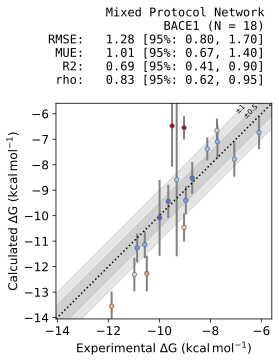

In [15]:
%matplotlib inline
%config InlineBackend.figure_formats = ['svg']
import json
from gufe.tokenization import JSON_HANDLER
from cinnabar import plotting
import requests

# Load the experimental values from the provided JSON URL
experimental_data_url = "https://raw.githubusercontent.com/OpenFreeEnergy/openfe-benchmarks/refs/heads/main/openfe_benchmarks/data/benchmark_systems/scaffold_hopping/bace_baumann/experimental_binding_data.json"

response = requests.get(experimental_data_url, timeout=30)
response.raise_for_status()
experimental_data = json.loads(response.text, cls=JSON_HANDLER.decoder)

# Add the data to FEMap for plotting
for ligand_name, exp_data in experimental_data.items():
    fe_map.add_experimental_measurement(
        label=ligand_name,
        value=exp_data["dg"],
        uncertainty=0.0 * unit.kilocalorie_per_mole,
    )

# Get the shift value to align the MLE estimates with the experimental values
exp_data = fe_map.get_absolute_dataframe()
exp_data = exp_data[exp_data["computational"] == False]["DG (kcal/mol)"].values

# Plot the results
plotting.plot_DGs(
    fe_map,
    source="MLE",
    target_name="BACE1",
    title="Mixed Protocol Network",
    figsize=5,
    shift=exp_data.mean(),
)

# Recap

- **openfe** provides a number of free energy protocols, any number of which can be combined into a single alchemical campaign.
- The protocols should be configured to use the same force field and settings should be adjusted to ensure consistency between protocols.
- Each protocol has different requirements for the `ChemicalSystem` compositions used to represent transformation end states; take care to use the correct systems for each protocol.
- `Transformations` containing any **openfe** protocol can be written to disk for execution using the [openfe quickrun CLI](https://docs.openfree.energy/en/stable/guide/introduction.html#cli-workflow).
- Analysis of a mixed-protocol network is not currently possible via the CLI; however, results can be gathered and combined using the API, as demonstrated above.

